# Exercise 5.4.3: training a postprocessing network
In this exercise, we will train a model for a postprocessing task as described in Section 5. 

Follow these steps for each inverse problem:

1. First, we implement an ImageDataset child class to generate ellipses and rectangles.
2. Define the forward tomographic operator with angles in $[0, \pi/2]$.
3. Define the reconstruction architecture. The postprocessing architecture is given by $\mathcal R_\theta = \Phi_\theta \circ A^\dagger$, which can be realized in DeepInverse via [ArtifactRemoval model](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.ArtifactRemoval.html). For $\Phi_\theta$ you can use [U-Net](https://arxiv.org/pdf/1505.04597) or a simpler [DnCNN](http://deepinv.github.io/deepinv/api/stubs/deepinv.models.DnCNN.html).
5. Train the reconstruction network on ellipses. At each training epoch, plot the PSNR of reconstructions and example images of source, measurements, and reconstruction.
6. Test the trained network on rectangles and compare the PSNR before and after training on the testset.

## Change runtime type and install DeepInverse package
First, we install the deepinverse library. Remeber to change the runtime of this notebook select ``Runtime`` -> ``Change runtime type`` and pick an available hardware accelerator.

In [ ]:
!pip install git+https://github.com/deepinv/deepinv.git#egg=deepinv

  Cloning https://github.com/deepinv/deepinv.git to /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Running command git clone --filter=blob:none --quiet https://github.com/deepinv/deepinv.git /tmp/pip-install-e1lcznm5/deepinv_1bad9b5c52884c469583ec31b815fd6e
  Resolved https://github.com/deepinv/deepinv.git to commit f304b6adc964e0054fd182d1044c7af11d2d116a
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━

In [1]:
import deepinv as dinv
from torch.utils.data import DataLoader
import torch
from pathlib import Path
from torchvision import transforms
from deepinv.utils.demo import load_dataset

import matplotlib.pyplot as plt

# Setup paths for data loading and checkpoints

In [2]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "measurements"
CKPT_DIR = BASE_DIR / "ckpts"

# Set the global random seed from pytorch to ensure reproducibility of the example.
torch.manual_seed(0)

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

Selected GPU 0 with 4834.4375 MiB free memory


# Generate dataset
We create a simple dataset class for generating images of ellipses and rectangles. As a basis, we use [PlaceholderDataset](https://deepinv.github.io/deepinv/_modules/deepinv/datasets/utils.html#PlaceholderDataset) class. 
Use `torch.randint` (https://docs.pytorch.org/docs/stable/generated/torch.randint.html) to generate random points and define random shapes.

In [3]:
class ShapeDataset(dinv.datasets.ImageDataset):
    shape_ellipse: bool = True

    def __init__(self, n=1, shape=(1, 64, 64), shape_ellipse = True):
        self.n = n # number of images in the dataset
        self.shape = shape # shape of images in order (number of channels, width, height)
        self.shape_ellipse = shape_ellipse # ellipse or rectangle?

    def __len__(self):
        return self.n


    def __getitem__(self, index):
        # This function should return 1 tensor of size self.shape, either a rectangle or an ellipse
        nx = self.shape[1]
        ny = self.shape[2]

        # Create index grid using torch.arange and torch.meshgrid
        xgrid = torch.arange(nx)
        ygrid = torch.arange(ny)
        grid_x, grid_y = torch.meshgrid(xgrid, ygrid, indexing='ij')
                
        if self.shape_ellipse:
            # Generate a random ellipse
            # Recall that an ellipse is given by the equation (x - x_0)^2 / a^2 + (y - y_0)^2/b^2 <= 1,
            # where (x_0, y_0) is the center and (a,b) define the length of the sides 
            
            # Radius of ellipse
            r = torch.randint(low = max([nx,ny])//4, high=max([nx,ny])//2,size=[1])

            # Center point
            c1 = torch.randint(low=nx//4, high=nx*3//4,size=[1])
            c2 = torch.randint(low=ny//4, high=ny*3//4,size=[1])

            # Length of sides
            s = torch.randn(size=[2])
            s = s.abs()/torch.norm(s)
            
            x = ((grid_x - c1)/s[0]).pow(2) + ((grid_y - c2)/s[1]).pow(2) < r.pow(2)
            return x[None,].float()
        else:
            # Generate a random rectangle
            # Recall that rectangle is defined by x_0 <= x <= x_1 and y_0 <= y <= y_1,
            # where (x_0, y_0) is its bottom left point and (x_1, y_1) is its top right point
            
            x1 = torch.randint(high=nx,size=[1])
            x2 = torch.randint(high=nx,size=[1])
            
            # Why do we need this?
            left= x1.minimum(x2)
            right = x1.maximum(x2)
            
            c1 = (left <= grid_x).logical_and(right >= grid_x) # Check x conditions (see torch.logical_and)
            
            y1 = torch.randint(high=ny,size=[1])
            y2 = torch.randint(high=ny,size=[1])
            
            bottom= y1.minimum(y2)
            top = y1.maximum(y2)
            
            c2 = (bottom <= grid_y).logical_and(top >= grid_y) # Check y conditions 
            c3 = c2.logical_and(c1)
            return c3[None,].float()

In [4]:
operation = "tomography"
train_dataset_name = "ellipses"
test_dataset_name = "square"
img_size = 128 if torch.cuda.is_available() else 32

n_images_train = 128 
n_images_test = 32

# Why do we choose shape as (1,img_size,img_size)?
train_dataset = ShapeDataset(n=n_images_train, shape=(1,img_size, img_size), shape_ellipse = True)
val_dataset = ShapeDataset(n=n_images_test, shape=(1,img_size, img_size), shape_ellipse = True)
test_dataset = ShapeDataset(n=n_images_test, shape=(1,img_size, img_size), shape_ellipse = False)

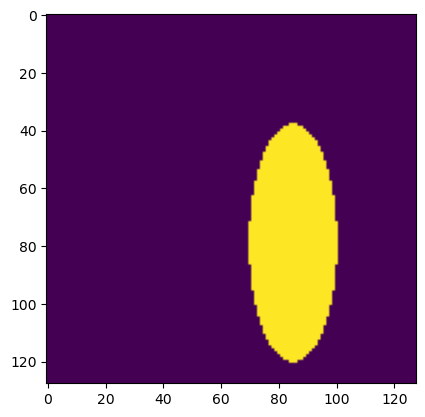

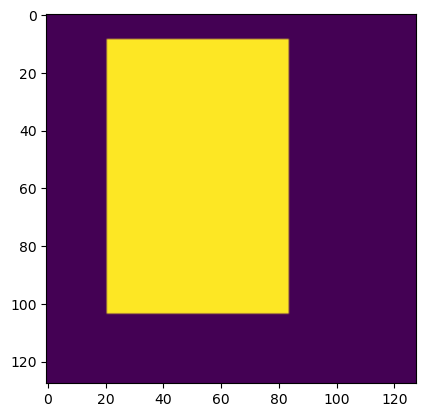

In [5]:
# Plot examples of the generated images 

# From the train set
x_tr = train_dataset[0]
plt.imshow(x_tr[0])
plt.show()

# From the test set
x_test = test_dataset[0]
plt.imshow(x_test[0])
plt.show()

# Define forward operator and prepare dataloaders
Define the forward tomographic operator with 90 equally spaced angles in $[0, \pi/2]$. See `torch.linspace` (https://docs.pytorch.org/docs/stable/generated/torch.linspace.html#torch-linspace) for details. 

In [6]:
n_channels = 3  # 3 for color images, 1 for gray-scale images
probability_mask = 0.5  # probability to mask pixel

# Generate inpainting operator
physics = dinv.physics.Tomography(
    img_width=img_size,
    angles=torch.linspace(0, 90, steps=90).to(device), # in degrees
    normalize=False,
    device=device,
    # noise_model=dinv.physics.GaussianNoise(sigma=noise_level_img), # optional complication
)

# For some problems, it is more convenient to pregenerate the measurements.
# Later, we can set online_measurements = False for Trainer
# It can be done via generate_dataset function
# n_images_max = (
#     1000 if torch.cuda.is_available() else 50
# )  # maximal number of images used for training

# my_dataset_name = "demo_training_tomograpy"
# measurement_dir = DATA_DIR / train_dataset_name / operation
# deepinv_datasets_path = dinv.datasets.generate_dataset(
#     train_dataset=train_dataset,
#     test_dataset=test_dataset,
#     physics=physics,
#     device=device,
#     save_dir=measurement_dir,
#     train_datapoints=n_images_max,
#     num_workers=num_workers,
#     dataset_filename=str(my_dataset_name),
# )

# train_dataset = dinv.datasets.HDF5Dataset(path=deepinv_datasets_path, train=True)
# test_dataset = dinv.datasets.HDF5Dataset(path=deepinv_datasets_path, train=False)

# deepinv_datasets_path_val = dinv.datasets.generate_dataset(
#     train_dataset=val_dataset,
#     test_dataset=None,
#     physics=physics,
#     device=device,
#     save_dir=measurement_dir,
#     train_datapoints=n_images_max,
#     num_workers=num_workers,
#     dataset_filename=str(my_dataset_name),
# )
# val_dataset = dinv.datasets.HDF5Dataset(path=deepinv_datasets_path_val, train=True)

num_workers = 4 if torch.cuda.is_available() else 1

train_batch_size = 16 if torch.cuda.is_available() else 1
test_batch_size = 16 if torch.cuda.is_available() else 1

# Set up dataloaders. Do we need to shuffle in this setup?

train_dataloader = DataLoader(
    train_dataset, batch_size=train_batch_size, num_workers=num_workers, shuffle=False
)

val_dataloader = DataLoader(
    val_dataset, batch_size=test_batch_size, num_workers=num_workers, shuffle=False
)

test_dataloader = DataLoader(
    test_dataset, batch_size=test_batch_size, num_workers=num_workers, shuffle=False
)

# Set up the reconstruction network

Set up reconstruction model $R_\theta = \Phi_\theta \circ A^\dagger$ based on [ArtifactRemoval model](https://deepinv.github.io/deepinv/api/stubs/deepinv.models.ArtifactRemoval.html).
Note we can pass the argument ``mode=direct``, ``mode=adjoint`` or ``mode=pinv``. Which one should be used here?

In [7]:
# choose backbone model
backbone = dinv.models.UNet(
    in_channels=1, out_channels=1, scales=3, batch_norm=False
).to(device)

# choose a reconstruction architecture
model = dinv.models.ArtifactRemoval(backbone, mode='pinv')

print(model)

ArtifactRemoval(
  (backbone_net): UNet(
    (Maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (Conv1): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Up3): Sequential(
      (0): Upsample(scale_factor=2.0, mode='nearest')
      (1): Conv2d(256, 128, kernel_size=(3, 3), str

# Train the model
We train the model using the [deepinv.Trainer](https://deepinv.github.io/deepinv/api/stubs/deepinv.Trainer.html#deepinv.Trainer) class.

We perform supervised learning and use the mean squared error as loss function. This can be easily done using the [deepinv.loss.SupLoss](https://deepinv.github.io/deepinv/api/stubs/deepinv.loss.SupLoss.html#deepinv.loss.SupLoss) class.


In [13]:
verbose = True  # print training information
wandb_vis = False  # plot curves and images in Weight&Bias

epochs = 200  # choose training epochs
learning_rate = 5e-4

# choose training losses
losses = dinv.loss.SupLoss(metric=dinv.metric.MSE())

# choose optimizer and scheduler
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-8)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=int(epochs * 0.8))
trainer = dinv.Trainer(
    model,
    device=device,
    save_path=str(CKPT_DIR / operation ),
    verbose=verbose,
    wandb_vis=wandb_vis,
    physics=physics,
    epochs=epochs,
    scheduler=scheduler,
    losses=losses,
    optimizer=optimizer,
    show_progress_bar=False,  # disable progress bar for better vis in sphinx gallery.
    train_dataloader=train_dataloader,
    eval_dataloader=val_dataloader,
    plot_images=False,
    plot_measurements=True,
    online_measurements=True,
    ckp_interval = 5,
    no_learning_method = 'A_dagger'
)

In [14]:
trainer.train()

The model has 2066497 trainable parameters


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1352: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train()


Train epoch 0: TotalLoss=0.014, PSNR=20.422
Eval epoch 0: PSNR=21.826
Best model saved at epoch 1
Train epoch 1: TotalLoss=0.006, PSNR=22.539
Eval epoch 1: PSNR=22.645
Best model saved at epoch 2
Train epoch 2: TotalLoss=0.004, PSNR=24.364
Eval epoch 2: PSNR=25.554
Best model saved at epoch 3
Train epoch 3: TotalLoss=0.003, PSNR=25.695
Eval epoch 3: PSNR=25.763
Best model saved at epoch 4
Train epoch 4: TotalLoss=0.002, PSNR=26.802
Eval epoch 4: PSNR=28.018
Best model saved at epoch 5
Train epoch 5: TotalLoss=0.002, PSNR=28.468
Eval epoch 5: PSNR=29.647
Best model saved at epoch 6
Train epoch 6: TotalLoss=0.001, PSNR=29.987
Eval epoch 6: PSNR=30.809
Best model saved at epoch 7
Train epoch 7: TotalLoss=0.001, PSNR=30.939
Eval epoch 7: PSNR=32.17
Best model saved at epoch 8
Train epoch 8: TotalLoss=0.001, PSNR=30.983
Eval epoch 8: PSNR=31.429
Train epoch 9: TotalLoss=0.001, PSNR=32.031
Eval epoch 9: PSNR=32.112
Train epoch 10: TotalLoss=0.001, PSNR=32.309
Eval epoch 10: PSNR=32.015
Train

ArtifactRemoval(
  (backbone_net): UNet(
    (Maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (Conv1): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (Up3): Sequential(
      (0): Upsample(scale_factor=2.0, mode='nearest')
      (1): Conv2d(256, 128, kernel_size=(3, 3), str

# Test the network
We can now test the trained network using the [deepinv.test()](https://deepinv.github.io/deepinv/api/stubs/deepinv.test.html#deepinv.test) function.

The testing function will compute test_psnr metrics and plot and save the results.

Model, optimizer, scheduler, epoch_start successfully loaded from checkpoint: ckpts/tomography/26-01-23-14:32:02/ckp_best.pth.tar


/homes/numerik/melnyk/scratch/anaconda3_new/lib/python3.13/site-packages/deepinv/training/trainer.py:1544: UserWarning: non_blocking_transfers=True but DataLoader.pin_memory=False; set pin_memory=True to overlap host-device copies with compute.
  self.setup_train(train=False)


Eval epoch 0: PSNR=49.286, PSNR no learning=23.304


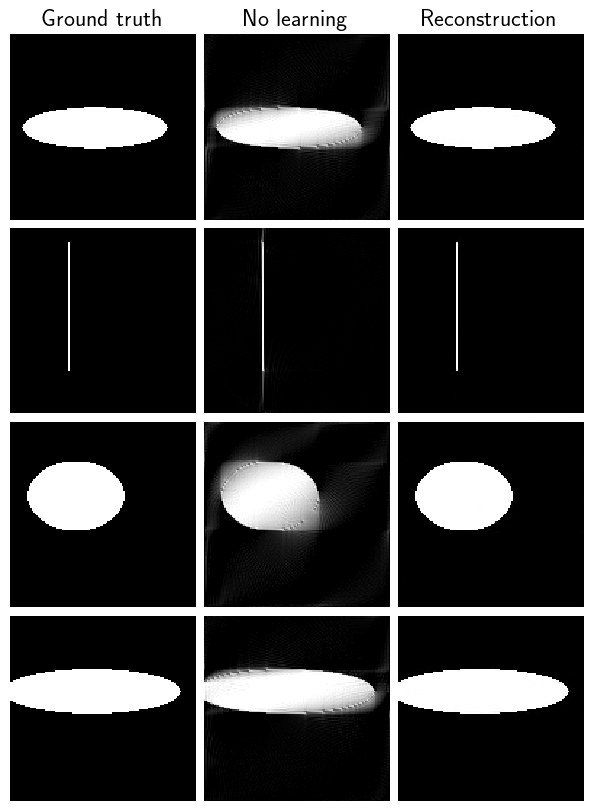

Test results:
PSNR no learning: 23.304 +- 5.800
PSNR: 49.286 +- 2.042


{'PSNR no learning': 23.303898811340332,
 'PSNR no learning_std': 5.800465691786472,
 'PSNR': 49.285987854003906,
 'PSNR_std': 2.0416010025019404}

In [15]:
# load model with best validation PSNR
model = trainer.load_best_model()

trainer.plot_images = True
trainer.test(val_dataloader)

Eval epoch 0: PSNR=40.174, PSNR no learning=25.836


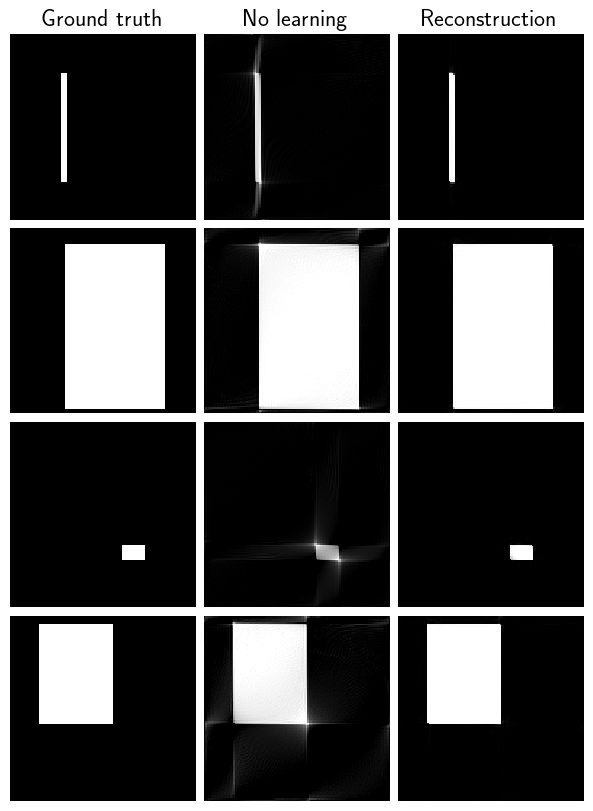

Test results:
PSNR no learning: 25.836 +- 4.570
PSNR: 40.174 +- 1.803


{'PSNR no learning': 25.835814476013184,
 'PSNR no learning_std': 4.570413666582477,
 'PSNR': 40.173770904541016,
 'PSNR_std': 1.8034909347266614}

In [16]:
trainer.test(test_dataloader)

# Test reconstruction on Shepp-Logan phantom

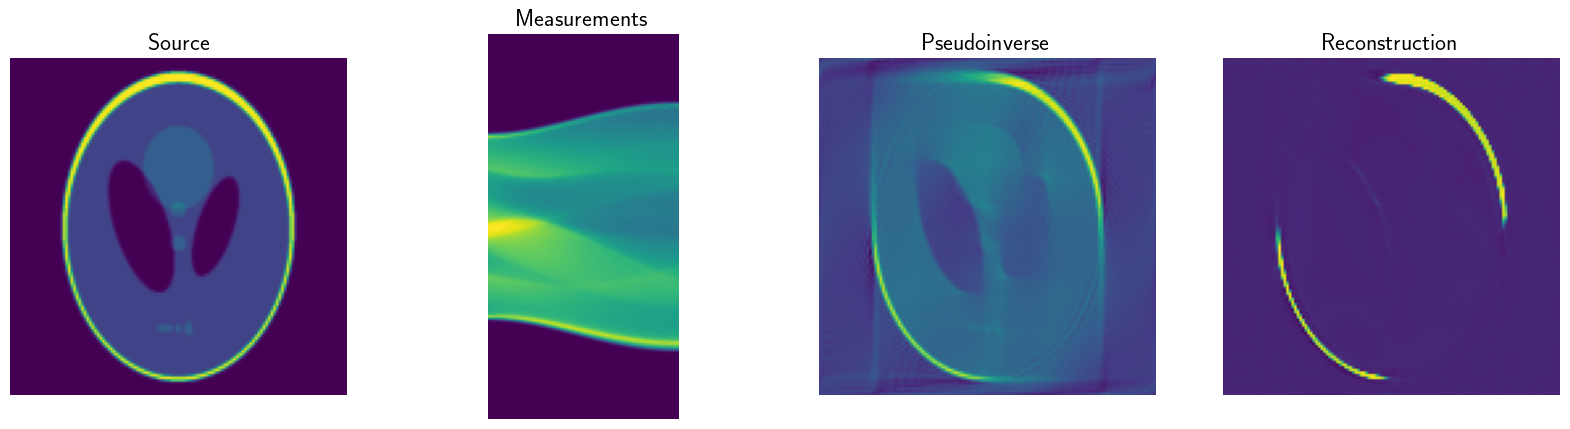

In [17]:
x = dinv.utils.load_example(
    "SheppLogan.png",
    img_size=img_size,
    grayscale=True,
    resize_mode="resize",
    device=device,
)

y = physics(x)
x_pinv= physics.A_dagger(y)
y_hat = model(y,physics)

plt.subplots(1, 4, figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(x[0,0].cpu())
plt.axis("off")
plt.title('Source')

plt.subplot(1, 4, 2)
plt.imshow(y[0,0].cpu())
plt.axis("off")
plt.title('Measurements')

plt.subplot(1, 4, 3)
plt.imshow(x_pinv[0,0].cpu())
plt.axis("off")
plt.title('Pseudoinverse')

plt.subplot(1, 4, 4)
plt.imshow(y_hat[0,0].detach().cpu())
plt.axis("off")
plt.title('Reconstruction')

plt.show()